# 07 - Compare a 10-feature LightGBM baseline with logistic regression

**Question:** can boosted decision trees improve future-week predictions using the same ten source features?

This notebook is self-contained: it loads the data, fits both models, compares their probabilities, and saves small reports. Start with sections 1-6 for the core workflow, then study the diagnostics.

- Training: weeks **0-51**.
- Development validation: weeks **52-71**.
- Locked holdout: weeks **72-91**, excluded from the base-table read and never scored.
- Logistic regression: training-median imputation, missing indicators, and scaling.
- LightGBM: raw numerical values with native `NaN` handling; zeros remain real values.

The comparison holds the source features and application cohorts fixed. Preprocessing differs appropriately by model family. Validation selects the LightGBM tree count, so the reported validation metrics are development results, not an independent final test.

## 1. Imports and configuration

Install the project's pinned dependencies using `python -m pip install -r requirements.txt` in the same Python environment as your notebook kernel. This notebook does not install packages automatically.

LightGBM adds decision trees sequentially. A limited number of leaves and a minimum number of applications per leaf help control complexity. We start with one fixed configuration rather than running a large parameter search.

In [1]:
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import gc
import hashlib
import json
import os
import platform

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, log_loss,
    precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
N_JOBS = min(4, os.cpu_count() or 1)
TRAIN_WEEKS = (0, 51)
VALIDATION_WEEKS = (52, 71)
HOLDOUT_WEEKS = (72, 91)
EARLY_STOPPING_ROUNDS = 75

FEATURES = [
    "credamount_770A", "annuity_780A", "maininc_215A",
    "applications30d_658L", "numactivecreds_622L", "totaldebt_9A",
    "avgdbddpdlast24m_3658932P", "avgdpdtolclosure24_3658938P",
    "clientscnt12m_3712952L", "price_1097A",
]

project_dir = next(
    (p for p in (Path.cwd(), Path.cwd().parent)
     if (p / "data/parquet_files/train/train_base.parquet").exists()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Run from the repository root or notebooks/ and download the Parquet files first."
    )

train_dir = project_dir / "data/parquet_files/train"
report_dir = project_dir / "reports/baseline_10_lightgbm"
artifact_dir = project_dir / "artifacts"
report_dir.mkdir(parents=True, exist_ok=True)
artifact_dir.mkdir(parents=True, exist_ok=True)

print("LightGBM version:", lgb.__version__)
print("CPU threads:", N_JOBS)
print("Source features:", len(FEATURES))

LightGBM version: 4.7.0
CPU threads: 4
Source features: 10


## 2. Read only the required columns and join by application ID

The base-table filter excludes weeks 72-91 before loading targets. The two static files are row partitions of one logical table: concatenate them, then join by `case_id`. The static read loads only the ID and ten predictors.

The checks below reject duplicate IDs, unmatched applications, non-binary targets, or infinite feature values. Missing numerical values are allowed.

In [2]:
base_df = pd.read_parquet(
    train_dir / "train_base.parquet",
    columns=["case_id", "WEEK_NUM", "target"],
    filters=[("WEEK_NUM", ">=", 0), ("WEEK_NUM", "<=", VALIDATION_WEEKS[1])],
)
static_df = pd.concat(
    [
        pd.read_parquet(
            train_dir / f"train_static_0_{part}.parquet",
            columns=["case_id", *FEATURES],
        )
        for part in (0, 1)
    ],
    ignore_index=True,
)

assert base_df["case_id"].notna().all() and base_df["case_id"].is_unique
assert static_df["case_id"].notna().all() and static_df["case_id"].is_unique

df = base_df.merge(
    static_df, on="case_id", how="left", validate="one_to_one", indicator=True,
)
assert df["_merge"].eq("both").all(), "Some base applications have no static row."
df = df.drop(columns="_merge")
assert df["target"].isin([0, 1]).all()
assert df["WEEK_NUM"].between(0, 71).all()
assert not np.isinf(df[FEATURES].to_numpy()).any()

del base_df, static_df
gc.collect()

print(f"Development applications: {len(df):,}")
print(f"Joined table memory: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MiB")

Development applications: 1,314,456
Joined table memory: 130.4 MiB


## 3. Create the chronological training and validation sets

There is no random train/test split and no resampling of the default class. Both models see exactly the same training targets and are compared on the same later applications.

The full-data row counts are checked to prevent accidentally comparing a partial download against the saved full-data baseline. Missing-value rates below are calculated on training rows only.

In [3]:
train_df = df.loc[df["WEEK_NUM"].between(*TRAIN_WEEKS)].reset_index(drop=True)
validation_df = df.loc[df["WEEK_NUM"].between(*VALIDATION_WEEKS)].reset_index(drop=True)
del df
gc.collect()

assert len(train_df) == 1_065_921, "Expected the full weeks 0-51 training cohort."
assert len(validation_df) == 248_535, "Expected the full weeks 52-71 validation cohort."
assert set(train_df["case_id"]).isdisjoint(validation_df["case_id"])

X_train = train_df[FEATURES]
y_train = train_df["target"]
X_valid = validation_df[FEATURES]
y_valid = validation_df["target"]

split_summary = pd.DataFrame([
    {"split": name, "first_week": int(part["WEEK_NUM"].min()),
     "last_week": int(part["WEEK_NUM"].max()), "rows": len(part),
     "defaults": int(part["target"].sum()), "default_rate": part["target"].mean()}
    for name, part in (("training", train_df), ("validation", validation_df))
])
split_summary.to_csv(report_dir / "split_summary.csv", index=False)
display(split_summary)
display(X_train.isna().mean().rename("training_missing_fraction").to_frame())

,split,first_week,last_week,rows,defaults,default_rate
0,training,0,51,1065921,32929,0.030893
1,validation,52,71,248535,10409,0.041881


,training_missing_fraction
credamount_770A,0.000000
annuity_780A,0.000000
maininc_215A,0.339775
applications30d_658L,0.000000
numactivecreds_622L,0.000000
totaldebt_9A,0.000002
avgdbddpdlast24m_3658932P,0.423792
avgdpdtolclosure24_3658938P,0.327221
clientscnt12m_3712952L,0.000000
price_1097A,0.131740


## 4. Fit the logistic regression reference

This reproduces notebook 05's model on the same training cohort. Refitting makes the notebook runnable after cloning, because trained artifacts are intentionally excluded from Git.

The imputer and scaler learn only from training rows. The labels are used by the classifier, not included as predictors.

In [4]:
logistic_model = Pipeline([
    ("preprocess", Pipeline([
        ("imputer", SimpleImputer(
            strategy="median", add_indicator=True, keep_empty_features=True,
        )),
        ("scaler", StandardScaler()),
    ])),
    ("model", LogisticRegression(
        max_iter=500, solver="lbfgs", class_weight=None, random_state=RANDOM_STATE,
    )),
])

started = perf_counter()
logistic_model.fit(X_train, y_train)
logistic_seconds = perf_counter() - started
logistic_train_probability = logistic_model.predict_proba(X_train)[:, 1]
logistic_valid_probability = logistic_model.predict_proba(X_valid)[:, 1]
print(f"Logistic regression fitted in {logistic_seconds:.1f} seconds")

Logistic regression fitted in 4.0 seconds


## 5. Fit LightGBM with early stopping

- `objective="binary"`: learn default probabilities using binary log loss.
- `num_leaves=15`: keep each tree relatively small.
- `min_child_samples=200`: require enough training examples in each leaf.
- `learning_rate=0.05`: each additional tree makes a modest adjustment.
- `n_estimators=1500`: an upper limit; validation selects the useful tree count.
- `zero_as_missing=False`: zero debt and zero application counts remain valid zeros.

Numerical missing values remain `NaN`; no median imputation, scaling, or extra missing-indicator columns are required for this experiment. Class weights remain neutral to avoid changing the training class distribution.

Early stopping monitors **validation log loss**, not training loss. Validation is part of model selection and must not be presented as a final untouched test.

In [5]:
lightgbm_parameters = {
    "objective": "binary",
    "metric": "binary_logloss",
    "boosting_type": "gbdt",
    "n_estimators": 1500,
    "learning_rate": 0.05,
    "num_leaves": 15,
    "max_depth": 5,
    "min_child_samples": 200,
    "reg_lambda": 5.0,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.9,
    "zero_as_missing": False,
    "random_state": RANDOM_STATE,
    "n_jobs": N_JOBS,
    "deterministic": True,
    "force_col_wise": True,
    "verbosity": -1,
}
lightgbm_model = lgb.LGBMClassifier(**lightgbm_parameters)

started = perf_counter()
lightgbm_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_valid, y_valid)],
    eval_names=["training", "validation"],
    callbacks=[
        lgb.early_stopping(
            EARLY_STOPPING_ROUNDS, first_metric_only=True, verbose=True,
        ),
        lgb.log_evaluation(period=100),
    ],
)
lightgbm_seconds = perf_counter() - started

lightgbm_train_probability = lightgbm_model.predict_proba(X_train)[:, 1]
lightgbm_valid_probability = lightgbm_model.predict_proba(X_valid)[:, 1]

print("Selected tree count:", lightgbm_model.best_iteration_)
print(f"LightGBM fitted in {lightgbm_seconds:.1f} seconds")
print("Validation log loss at selected iteration:",
      lightgbm_model.best_score_["validation"]["binary_logloss"])

C:\Users\DOWNLOAD\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 75 rounds


[100]	training's binary_logloss: 0.129215	validation's binary_logloss: 0.161829


[200]	training's binary_logloss: 0.128505	validation's binary_logloss: 0.161082


[300]	training's binary_logloss: 0.128026	validation's binary_logloss: 0.160766


...

[500]	training's binary_logloss: 0.127278	validation's binary_logloss: 0.160444


[600]	training's binary_logloss: 0.126989	validation's binary_logloss: 0.160385


[700]	training's binary_logloss: 0.126728	validation's binary_logloss: 0.160328


Early stopping, best iteration is:
[674]	training's binary_logloss: 0.126784	validation's binary_logloss: 0.160312
Evaluated only: binary_logloss


Selected tree count: 674
LightGBM fitted in 48.5 seconds
Validation log loss at selected iteration: 0.16031177650627917


## 6. Compare ranking and probability quality

ROC AUC and Gini measure ranking. Average precision focuses on the rare default class. Log loss and Brier score measure probability quality; lower is better. The mean prediction versus observed default rate is a useful aggregate calibration check, but does not prove calibration within every risk group.

The constant model predicts the training default rate for everyone. The new model earns its place only through measured development performance.

In [6]:
def metric_row(name, target, probability):
    probability = np.asarray(probability)
    assert probability.shape == (len(target),)
    assert np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    auc = roc_auc_score(target, probability)
    return {
        "model": name, "rows": len(target),
        "actual_default_rate": float(np.mean(target)),
        "mean_predicted_probability": float(probability.mean()),
        "roc_auc": auc, "gini": 2 * auc - 1,
        "average_precision": average_precision_score(target, probability),
        "log_loss": log_loss(target, probability),
        "brier_score": brier_score_loss(target, probability),
    }

validation_probabilities = {
    "Constant": np.full(len(y_valid), float(y_train.mean())),
    "Logistic regression": logistic_valid_probability,
    "LightGBM": lightgbm_valid_probability,
}
performance = pd.DataFrame([
    metric_row(name, y_valid, probability)
    for name, probability in validation_probabilities.items()
]).set_index("model")
performance.to_csv(report_dir / "performance_metrics.csv")
display(performance.round(6))

training_performance = pd.DataFrame([
    metric_row("Logistic regression", y_train, logistic_train_probability),
    metric_row("LightGBM", y_train, lightgbm_train_probability),
]).set_index("model")
training_performance.to_csv(report_dir / "training_metrics.csv")
print("Training metrics (diagnostics, not evidence of future performance):")
display(training_performance.round(6))

difference = (
    performance.loc["LightGBM"] - performance.loc["Logistic regression"]
).loc[["roc_auc", "gini", "average_precision", "log_loss", "brier_score"]]
print("LightGBM minus logistic regression:")
display(difference.rename("difference").to_frame().round(6))

,rows,actual_default_rate,mean_predicted_probability,roc_auc,gini,average_precision,log_loss,brier_score
model,,,,,,,,
Constant,248535,0.041881,0.030893,0.500000,0.000000,0.041881,0.175697,0.040248
Logistic regression,248535,0.041881,0.031706,0.608473,0.216947,0.072298,0.172443,0.040056
LightGBM,248535,0.041881,0.033174,0.726160,0.452321,0.125569,0.160312,0.038671


Training metrics (diagnostics, not evidence of future performance):


,rows,actual_default_rate,mean_predicted_probability,roc_auc,gini,average_precision,log_loss,brier_score
model,,,,,,,,
Logistic regression,1065921,0.030893,0.030893,0.569175,0.138350,0.046743,0.136406,0.029848
LightGBM,1065921,0.030893,0.030916,0.725008,0.450017,0.101018,0.126784,0.028971


LightGBM minus logistic regression:


,difference
roc_auc,0.117687
gini,0.235374
average_precision,0.053271
log_loss,-0.012131
brier_score,-0.001385


## 7. Inspect risk-group calibration and ranking curves

Group validation applications by similar predicted risk. Within each group, compare the mean prediction with the observed default rate. These groups are diagnostics, not a new feature and not a calibration transformation.

We do not fit a probability-calibration model on this validation set and then report its performance on the same rows.

,model,risk_bin,applications,defaults,mean_predicted_probability,observed_default_rate
0,Logistic regression,1,24854,749,0.02294,0.03014
1,Logistic regression,2,24853,718,0.02557,0.02889
2,Logistic regression,3,24854,804,0.02643,0.03235
3,Logistic regression,4,24853,769,0.02713,0.03094
4,Logistic regression,5,24854,773,0.02797,0.03110
5,Logistic regression,6,24853,819,0.02901,0.03295
6,Logistic regression,7,24853,932,0.03039,0.03750
7,Logistic regression,8,24854,1091,0.03247,0.04390
8,Logistic regression,9,24853,1408,0.03625,0.05665
9,Logistic regression,10,24854,2346,0.05891,0.09439


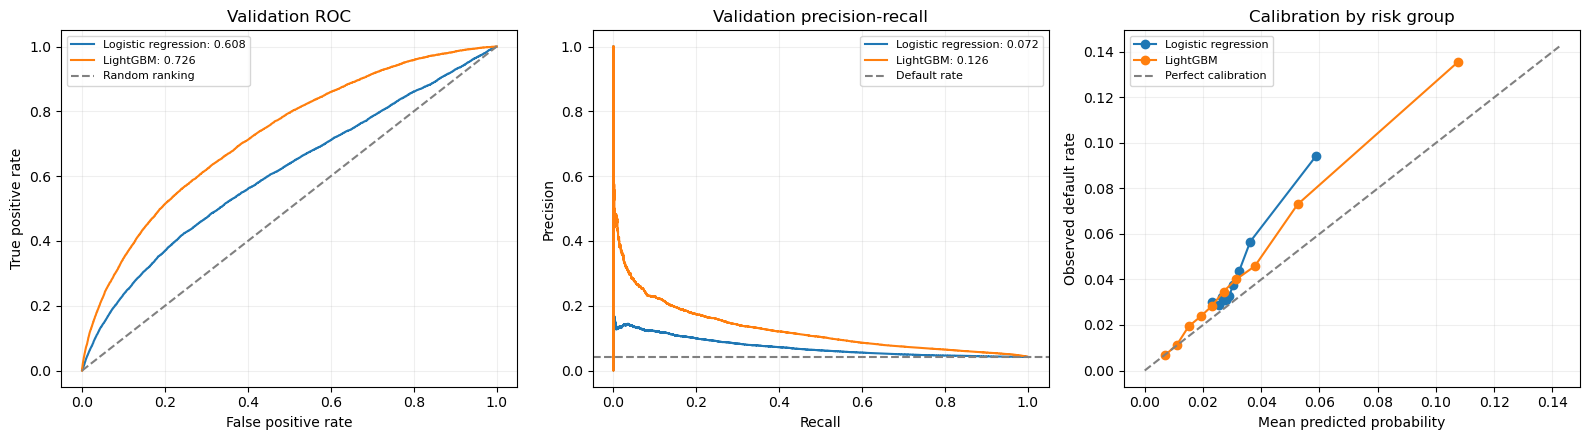

In [7]:
calibration_rows = []
for name in ("Logistic regression", "LightGBM"):
    grouped_predictions = pd.DataFrame({
        "target": y_valid.to_numpy(),
        "probability": validation_probabilities[name],
    })
    grouped_predictions["risk_bin"] = pd.qcut(
        grouped_predictions["probability"], q=10, duplicates="drop",
    )
    for bin_number, (interval, group) in enumerate(
        grouped_predictions.groupby("risk_bin", observed=True, sort=True), start=1
    ):
        calibration_rows.append({
            "model": name, "risk_bin": bin_number,
            "applications": len(group), "defaults": int(group["target"].sum()),
            "mean_predicted_probability": group["probability"].mean(),
            "observed_default_rate": group["target"].mean(),
        })

calibration_summary = pd.DataFrame(calibration_rows)
calibration_summary.to_csv(report_dir / "calibration_by_risk_group.csv", index=False)
display(calibration_summary.round(5))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name in ("Logistic regression", "LightGBM"):
    probability = validation_probabilities[name]
    false_positive, true_positive, _ = roc_curve(y_valid, probability)
    precision, recall, _ = precision_recall_curve(y_valid, probability)
    axes[0].plot(false_positive, true_positive,
                 label=f"{name}: {performance.loc[name, 'roc_auc']:.3f}")
    axes[1].plot(recall, precision,
                 label=f"{name}: {performance.loc[name, 'average_precision']:.3f}")
    group = calibration_summary.loc[calibration_summary["model"].eq(name)]
    axes[2].plot(group["mean_predicted_probability"],
                 group["observed_default_rate"], marker="o", label=name)

axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Random ranking")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="Validation ROC")
axes[1].axhline(y_valid.mean(), linestyle="--", color="grey", label="Default rate")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Validation precision-recall")
calibration_limit = max(
    calibration_summary["mean_predicted_probability"].max(),
    calibration_summary["observed_default_rate"].max(),
) * 1.05
axes[2].plot([0, calibration_limit], [0, calibration_limit], "--",
             color="grey", label="Perfect calibration")
axes[2].set(xlabel="Mean predicted probability", ylabel="Observed default rate",
            title="Calibration by risk group")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(report_dir / "ranking_and_calibration.png", dpi=140)
plt.show()

## 8. Check performance across validation weeks

A higher overall AUC does not establish consistent performance over time. Compare each model on the same 20 validation weeks. The slope and spread below are development diagnostics, not an official Kaggle leaderboard score.

A positive calibration gap means predicted risk exceeds observed risk; a negative gap means risk is underestimated.

,mean_weekly_gini,std_weekly_gini,minimum_weekly_gini,maximum_weekly_gini,weekly_gini_slope,negative_gini_weeks,mean_absolute_calibration_gap
model,,,,,,,
Logistic regression,0.214601,0.095192,-0.044421,0.393970,0.001332,1,0.011231
LightGBM,0.471004,0.066274,0.383337,0.698243,0.004972,0,0.010455


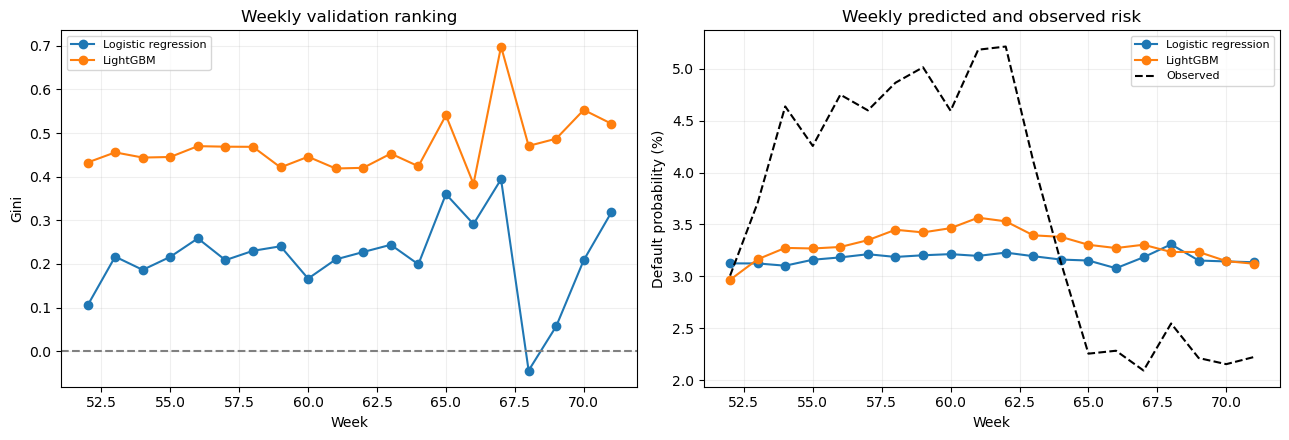

In [8]:
weekly_rows = []
for name in ("Logistic regression", "LightGBM"):
    predictions = pd.DataFrame({
        "WEEK_NUM": validation_df["WEEK_NUM"].to_numpy(),
        "target": y_valid.to_numpy(),
        "probability": validation_probabilities[name],
    })
    for week, group in predictions.groupby("WEEK_NUM", sort=True):
        row = metric_row(name, group["target"], group["probability"].to_numpy())
        row.update({
            "WEEK_NUM": int(week), "defaults": int(group["target"].sum()),
            "calibration_gap": group["probability"].mean() - group["target"].mean(),
        })
        weekly_rows.append(row)

weekly_metrics = pd.DataFrame(weekly_rows)
weekly_metrics.to_csv(report_dir / "weekly_validation_metrics.csv", index=False)

weekly_summary_rows = []
for name, group in weekly_metrics.groupby("model", sort=False):
    weekly_summary_rows.append({
        "model": name,
        "mean_weekly_gini": group["gini"].mean(),
        "std_weekly_gini": group["gini"].std(ddof=0),
        "minimum_weekly_gini": group["gini"].min(),
        "maximum_weekly_gini": group["gini"].max(),
        "weekly_gini_slope": np.polyfit(group["WEEK_NUM"], group["gini"], 1)[0],
        "negative_gini_weeks": int(group["gini"].lt(0).sum()),
        "mean_absolute_calibration_gap": group["calibration_gap"].abs().mean(),
    })
weekly_summary = pd.DataFrame(weekly_summary_rows).set_index("model")
weekly_summary.to_csv(report_dir / "weekly_validation_summary.csv")
display(weekly_summary.round(6))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, group in weekly_metrics.groupby("model", sort=False):
    axes[0].plot(group["WEEK_NUM"], group["gini"], marker="o", label=name)
    axes[1].plot(group["WEEK_NUM"], 100 * group["mean_predicted_probability"],
                 marker="o", label=name)
observed = weekly_metrics.loc[weekly_metrics["model"].eq("Logistic regression")]
axes[1].plot(observed["WEEK_NUM"], 100 * observed["actual_default_rate"],
             color="black", linestyle="--", label="Observed")
axes[0].axhline(0, color="grey", linestyle="--")
axes[0].set(xlabel="Week", ylabel="Gini", title="Weekly validation ranking")
axes[1].set(xlabel="Week", ylabel="Default probability (%)",
            title="Weekly predicted and observed risk")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(report_dir / "weekly_comparison.png", dpi=140)
plt.show()

## 9. Inspect training progress and feature usage

The loss curve explains why training stopped. Gain importance reports how much a feature helped reduce the training objective across tree splits. It is not a causal effect and is not a substitute for future-week feature-ablation experiments.

,feature,gain,split_count
7,avgdpdtolclosure24_3658938P,85986.467008,844
9,price_1097A,29148.345857,1758
6,avgdbddpdlast24m_3658932P,24727.265231,1154
1,annuity_780A,16176.418811,1723
0,credamount_770A,15682.720850,1391
5,totaldebt_9A,13101.001134,775
3,applications30d_658L,10138.030976,233
2,maininc_215A,8196.590018,1206
8,clientscnt12m_3712952L,1942.265309,109
4,numactivecreds_622L,1232.466592,163


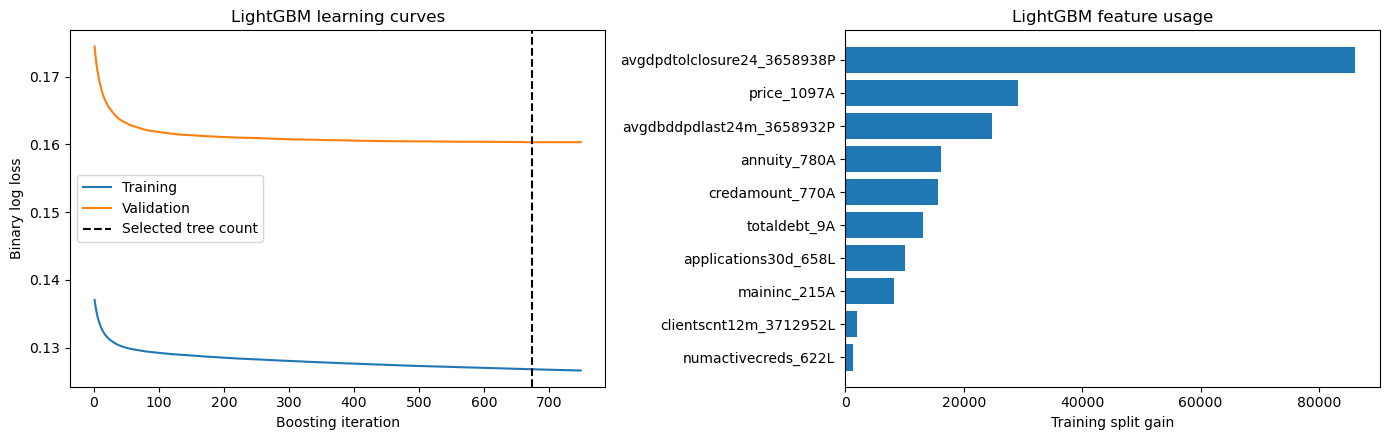

In [9]:
training_history = pd.DataFrame({
    "iteration": np.arange(
        1, len(lightgbm_model.evals_result_["validation"]["binary_logloss"]) + 1,
    ),
    "training_log_loss": lightgbm_model.evals_result_["training"]["binary_logloss"],
    "validation_log_loss": lightgbm_model.evals_result_["validation"]["binary_logloss"],
})
training_history.to_csv(report_dir / "training_history.csv", index=False)

feature_importance = pd.DataFrame({
    "feature": FEATURES,
    "gain": lightgbm_model.booster_.feature_importance(importance_type="gain"),
    "split_count": lightgbm_model.booster_.feature_importance(importance_type="split"),
}).sort_values("gain", ascending=False)
feature_importance.to_csv(report_dir / "feature_importance.csv", index=False)
display(feature_importance)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(training_history["iteration"], training_history["training_log_loss"],
             label="Training")
axes[0].plot(training_history["iteration"], training_history["validation_log_loss"],
             label="Validation")
axes[0].axvline(lightgbm_model.best_iteration_, linestyle="--", color="black",
                label="Selected tree count")
axes[0].set(xlabel="Boosting iteration", ylabel="Binary log loss",
            title="LightGBM learning curves")
axes[0].legend()
importance_plot = feature_importance.sort_values("gain")
axes[1].barh(importance_plot["feature"], importance_plot["gain"])
axes[1].set(xlabel="Training split gain", title="LightGBM feature usage")
fig.tight_layout()
fig.savefig(report_dir / "training_and_feature_importance.png", dpi=140)
plt.show()

## 10. Save reproducibility information and local scoring artifacts

Only small summary tables, figures, and the run manifest belong in Git. The fitted model and per-application predictions are generated locally and ignored.

The manifest records parameters, package versions, cohort fingerprints, and hashes of the three input files. Hashing reads these three files in chunks; it does not load the 26 GB competition dataset.

The artifact round-trip check verifies that reloading the saved model preserves predictions. At prediction time, keep the same ten column names and order; retain genuine zeros and represent missing numerical values as `NaN`.

In [10]:
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def cohort_fingerprint(part):
    case_ids = np.sort(part["case_id"].to_numpy(dtype=np.int64))
    return hashlib.sha256(case_ids.astype("<i8").tobytes()).hexdigest()

source_names = [
    "train_base.parquet", "train_static_0_0.parquet", "train_static_0_1.parquet",
]
package_names = [
    "lightgbm", "numpy", "pandas", "pyarrow", "scipy", "scikit-learn", "joblib",
]
manifest = {
    "experiment": "10-feature LightGBM versus logistic regression",
    "python_version": platform.python_version(),
    "package_versions": {name: version(name) for name in package_names},
    "source_features": FEATURES,
    "training_weeks": list(TRAIN_WEEKS),
    "validation_weeks": list(VALIDATION_WEEKS),
    "locked_holdout_weeks": list(HOLDOUT_WEEKS),
    "holdout_evaluated": False,
    "training_case_ids_sha256": cohort_fingerprint(train_df),
    "validation_case_ids_sha256": cohort_fingerprint(validation_df),
    "lightgbm_parameters": lightgbm_parameters,
    "logistic_parameters": {
        "max_iter": 500, "solver": "lbfgs", "class_weight": None,
        "random_state": RANDOM_STATE, "C": 1.0,
        "preprocessing": "training-median imputation, missing indicators, StandardScaler",
    },
    "early_stopping_metric": "validation binary_logloss",
    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
    "best_iteration": int(lightgbm_model.best_iteration_),
    "fit_seconds": {
        "logistic_regression": logistic_seconds,
        "lightgbm": lightgbm_seconds,
    },
    "source_files": {
        name: {
            "bytes": (train_dir / name).stat().st_size,
            "sha256": file_sha256(train_dir / name),
        }
        for name in source_names
    },
}
(report_dir / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2) + "\n", encoding="utf-8",
)

validation_predictions = validation_df[["case_id", "WEEK_NUM", "target"]].copy()
validation_predictions["logistic_probability"] = logistic_valid_probability
validation_predictions["lightgbm_probability"] = lightgbm_valid_probability
validation_predictions.to_parquet(
    report_dir / "validation_predictions.parquet", index=False,
)

artifact_path = artifact_dir / "baseline_10_lightgbm_trained_weeks_0_51.joblib"
joblib.dump({
    "lightgbm_model": lightgbm_model,
    "logistic_pipeline": logistic_model,
    "selected_features": FEATURES,
    "training_weeks": list(TRAIN_WEEKS),
    "validation_weeks": list(VALIDATION_WEEKS),
    "locked_holdout_weeks": list(HOLDOUT_WEEKS),
    "best_iteration": int(lightgbm_model.best_iteration_),
}, artifact_path)

reloaded = joblib.load(artifact_path)
np.testing.assert_allclose(
    reloaded["lightgbm_model"].predict_proba(X_valid.iloc[:128])[:, 1],
    lightgbm_valid_probability[:128], rtol=1e-12, atol=1e-12,
)
print("Saved model reload reproduces the first 128 validation predictions.")
display(validation_predictions.head(5))

Saved model reload reproduces the first 128 validation predictions.


,case_id,WEEK_NUM,target,logistic_probability,lightgbm_probability
0,42016,52,0,0.035105,0.022597
1,42347,52,0,0.024794,0.025492
2,42349,52,0,0.025080,0.030553
3,42358,52,0,0.025088,0.030553
4,42360,52,0,0.028360,0.038218


## 11. Read the result before choosing the next experiment

The report below is generated from this run, rather than assuming a more complex model must win. An AUC improvement alone does not prove well-calibrated probabilities or future stability.

The next experiments can add suitable static features, compare more time periods, and later test calibration with a separate development procedure. Keep the locked holdout unused until the approach is frozen.

Sources: [LightGBM features](https://lightgbm.readthedocs.io/en/stable/Features.html), [native missing values](https://lightgbm.readthedocs.io/en/stable/Advanced-Topics.html#missing-value-handle), and [early stopping](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.early_stopping.html).

In [11]:
logistic_result = performance.loc["Logistic regression"]
lightgbm_result = performance.loc["LightGBM"]
auc_change = lightgbm_result["roc_auc"] - logistic_result["roc_auc"]
loss_change = lightgbm_result["log_loss"] - logistic_result["log_loss"]
print(f"Validation AUC: logistic {logistic_result['roc_auc']:.4f}, "
      f"LightGBM {lightgbm_result['roc_auc']:.4f}, change {auc_change:+.4f}")
print(f"Validation log loss: logistic {logistic_result['log_loss']:.5f}, "
      f"LightGBM {lightgbm_result['log_loss']:.5f}, change {loss_change:+.5f}")
print(f"LightGBM mean prediction: {lightgbm_result['mean_predicted_probability']:.2%}; "
      f"observed rate: {lightgbm_result['actual_default_rate']:.2%}")
print(f"Selected trees: {lightgbm_model.best_iteration_}")
print("Locked holdout evaluated: False")
print("Inspect the weekly and risk-group diagnostics before selecting a model.")

Validation AUC: logistic 0.6085, LightGBM 0.7262, change +0.1177
Validation log loss: logistic 0.17244, LightGBM 0.16031, change -0.01213
LightGBM mean prediction: 3.32%; observed rate: 4.19%
Selected trees: 674
Locked holdout evaluated: False
Inspect the weekly and risk-group diagnostics before selecting a model.
